# EDA: поведение пользователей в OTTO

Исследуем события до начала последней недели данных. Последняя неделя отведена под validation и не участвует в метриках EDA.


In [1]:
import json
import os
from collections import Counter, defaultdict
from datetime import datetime, timedelta, timezone
from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TRAIN_PATH = '/kaggle/input/competitions/otto-recommender-system/train.jsonl'
DURATION_VALUES_PATH = '/kaggle/working/session_durations_ms.bin'

# Последний timestamp исходного файла; от него отсчитывается неделя validation.
DATA_END = datetime(2022, 8, 28, 21, 59, 59, 984000, tzinfo=timezone.utc)
VALIDATION_DAYS = 7
VALIDATION_START = DATA_END - timedelta(days=VALIDATION_DAYS)
VALIDATION_START_TS = int(VALIDATION_START.timestamp() * 1000)


## Размер набора и граница split

Считается число записей-сессий в файле. Последние семь суток по времени событий отводятся под validation; число сессий и событий по обе стороны границы считается при потоковой обработке ниже. Сессии с событиями до и после границы учитываются в обеих частях.


In [2]:
with open(TRAIN_PATH, 'r') as train_file:
    total_sessions = sum(1 for _ in train_file)

print(f'Всего записей-сессий: {total_sessions:,}')
print(f'Train: события раньше {VALIDATION_START.isoformat()}')
print(f'Validation: с {VALIDATION_START.isoformat()} по {DATA_END.isoformat()}')


Всего записей-сессий: 12,899,779
Train: события раньше 2022-08-21T21:59:59.984000+00:00
Validation: с 2022-08-21T21:59:59.984000+00:00 по 2022-08-28T21:59:59.984000+00:00


## Потоковые агрегаты

Второй проход обрабатывает события раньше границы validation. События после границы учитываются только для подсчёта размеров частей; метрики, таблицы и графики строятся только по train-событиям. Одна запись-сессия может содержать события в обеих частях, поэтому числа сессий train и validation могут пересекаться.

Переход `click → cart` считается двумя способами:

- **по сессиям:** в train-части сессии после просмотра встретилось добавление в корзину;
- **по товарам:** тот же `aid` сначала просмотрели, а затем добавили в корзину внутри train-части.

Аналогично считаются переходы `cart → order`. Воронка показывает последовательность событий, но не доказывает, что одно действие вызвало другое.


In [3]:
EVENT_TYPES = ('clicks', 'carts', 'orders')

# Split sizes are counted while reading the file; only train events feed EDA metrics.
train_event_count = 0
validation_event_count = 0
train_sessions_count = 0
validation_sessions_count = 0
sessions_crossing_boundary = 0

event_counts = Counter()
session_type_combinations = Counter()
first_event_type_counts = Counter()
last_event_type_counts = Counter()
session_length_counts = Counter()
daily_event_counts = defaultdict(Counter)
daily_session_stats = defaultdict(Counter)
funnel = Counter()

min_event_ts = float('inf')
max_event_ts = float('-inf')
# Длительности train-частей сессий записываются в файл.
duration_values = np.memmap(
    DURATION_VALUES_PATH, dtype='int64', mode='w+', shape=(total_sessions,)
)
duration_seen = 0
duration_sum_ms = 0
max_duration_ms = 0

# Счётчики по каждому aid охватывают все train-события.
top_item_counts = {event_type: Counter() for event_type in EVENT_TYPES}

with open(TRAIN_PATH, 'r') as train_file:
    for session_index, line in enumerate(train_file):
        record = json.loads(line)
        events = record['events']

        parsed_events = []
        session_aids = []
        session_types = set()
        session_has_train_events = False
        session_has_validation_events = False

        for event in events:
            ts = int(event['ts'])
            if ts >= VALIDATION_START_TS:
                validation_event_count += 1
                session_has_validation_events = True
                continue

            train_event_count += 1
            session_has_train_events = True
            aid_value = event['aid']
            event_type = event['type']
            event_counts[event_type] += 1
            session_types.add(event_type)

            aid = str(aid_value)
            parsed_events.append((ts, event_type, aid))
            min_event_ts = min(min_event_ts, ts)
            max_event_ts = max(max_event_ts, ts)

            event_day = datetime.fromtimestamp(ts / 1000, tz=timezone.utc).date().isoformat()
            daily_event_counts[event_day][event_type] += 1
            session_aids.append(aid)
            top_item_counts[event_type][int(aid_value)] += 1

        if session_has_train_events:
            train_sessions_count += 1
        if session_has_validation_events:
            validation_sessions_count += 1
        if session_has_train_events and session_has_validation_events:
            sessions_crossing_boundary += 1

        if not parsed_events:
            if session_index and session_index % 1_000_000 == 0:
                print(f'Обработано записей-сессий: {session_index + 1:,}')
            continue

        funnel['sessions'] += 1
        funnel['total_events'] += len(parsed_events)
        session_length_counts[len(parsed_events)] += 1

        combination = '+'.join(event_type for event_type in EVENT_TYPES if event_type in session_types)
        session_type_combinations[combination or 'no_known_type'] += 1
        has_clicks = 'clicks' in session_types
        has_carts = 'carts' in session_types
        has_orders = 'orders' in session_types
        funnel['sessions_with_clicks'] += int(has_clicks)
        funnel['sessions_with_carts'] += int(has_carts)
        funnel['sessions_with_orders'] += int(has_orders)
        funnel['sessions_with_clicks_and_carts'] += int(has_clicks and has_carts)
        funnel['sessions_with_carts_and_orders'] += int(has_carts and has_orders)
        funnel['sessions_with_all_three_types'] += int(has_clicks and has_carts and has_orders)

        timestamps = [row[0] for row in parsed_events]

        # Preserve the input sequence: OTTO events are already time-ordered within each session.
        event_types_in_order = [row[1] for row in parsed_events]
        first_event_type_counts[event_types_in_order[0]] += 1
        last_event_type_counts[event_types_in_order[-1]] += 1

        unique_aids = set(session_aids)
        funnel['item_session_pairs'] += len(session_aids)
        funnel['unique_item_session_pairs'] += len(unique_aids)
        funnel['repeat_item_events'] += len(session_aids) - len(unique_aids)

        duration_ms = max(timestamps) - min(timestamps)
        duration_values[duration_seen] = duration_ms
        duration_seen += 1
        duration_sum_ms += duration_ms
        max_duration_ms = max(max_duration_ms, duration_ms)

        start_day = datetime.fromtimestamp(timestamps[0] / 1000, tz=timezone.utc).date().isoformat()
        day_metrics = daily_session_stats[start_day]
        day_metrics['sessions'] += 1
        day_metrics['events'] += len(parsed_events)
        day_metrics['session_clicks'] += int(has_clicks)
        day_metrics['session_carts'] += int(has_carts)
        day_metrics['session_orders'] += int(has_orders)
        day_metrics['session_clicks_and_carts'] += int(has_clicks and has_carts)
        day_metrics['session_carts_and_orders'] += int(has_carts and has_orders)
        day_metrics['session_all_three_types'] += int(has_clicks and has_carts and has_orders)

        first_click_position = None
        first_cart_position = None
        first_cart_after_click_position = None
        has_cart_after_click = False
        has_order_after_cart = False
        has_order_after_cart_after_click = False

        first_click_by_aid = {}
        first_cart_after_click_by_aid = {}
        first_cart_by_aid = {}
        order_after_click_cart_by_aid = set()
        order_after_any_cart_by_aid = set()

        for position, (_, event_type, aid) in enumerate(parsed_events):
            if event_type == 'clicks':
                if first_click_position is None:
                    first_click_position = position
                first_click_by_aid.setdefault(aid, position)

            elif event_type == 'carts':
                if first_cart_position is None:
                    first_cart_position = position
                if first_click_position is not None and position > first_click_position:
                    has_cart_after_click = True
                    if first_cart_after_click_position is None:
                        first_cart_after_click_position = position
                first_cart_by_aid.setdefault(aid, position)
                if aid in first_click_by_aid:
                    first_cart_after_click_by_aid.setdefault(aid, position)

            elif event_type == 'orders':
                if first_cart_position is not None and position > first_cart_position:
                    has_order_after_cart = True
                if (first_cart_after_click_position is not None and
                        position > first_cart_after_click_position):
                    has_order_after_cart_after_click = True
                if aid in first_cart_after_click_by_aid:
                    order_after_click_cart_by_aid.add(aid)
                if aid in first_cart_by_aid:
                    order_after_any_cart_by_aid.add(aid)

        clicked_aids = set(first_click_by_aid)
        carted_clicked_aids = set(first_cart_after_click_by_aid)
        carted_aids = set(first_cart_by_aid)

        funnel['sessions_click_then_cart'] += int(has_cart_after_click)
        funnel['sessions_cart_then_order'] += int(has_order_after_cart)
        funnel['sessions_click_cart_order'] += int(has_order_after_cart_after_click)
        funnel['clicked_aid_session_pairs'] += len(clicked_aids)
        funnel['clicked_then_cart_aid_session_pairs'] += len(carted_clicked_aids)
        funnel['carted_aid_session_pairs'] += len(carted_aids)
        funnel['carted_then_order_aid_session_pairs'] += len(order_after_any_cart_by_aid)
        funnel['clicked_carted_then_order_aid_session_pairs'] += len(order_after_click_cart_by_aid)

        day_metrics['session_click_then_cart'] += int(has_cart_after_click)
        day_metrics['session_cart_then_order'] += int(has_order_after_cart)
        day_metrics['session_click_cart_order'] += int(has_order_after_cart_after_click)
        day_metrics['clicked_aid_session_pairs'] += len(clicked_aids)
        day_metrics['clicked_then_cart_aid_session_pairs'] += len(carted_clicked_aids)
        day_metrics['carted_aid_session_pairs'] += len(carted_aids)
        day_metrics['carted_then_order_aid_session_pairs'] += len(order_after_any_cart_by_aid)
        day_metrics['clicked_carted_then_order_aid_session_pairs'] += len(order_after_click_cart_by_aid)


        if session_index and session_index % 1_000_000 == 0:
            print(f'Обработано записей-сессий: {session_index + 1:,}')

print('Размер временного разделения:')
print(f'Всего записей-сессий: {total_sessions:,}')
print(f'Train: {train_sessions_count:,} сессий, {train_event_count:,} событий')
print(f'Validation: {validation_sessions_count:,} сессий, {validation_event_count:,} событий')
print(f'Сессий с событиями по обе стороны границы: {sessions_crossing_boundary:,}')

top_item_rows = []
for event_type, counts in top_item_counts.items():
    event_total = event_counts[event_type]
    top_counts = counts.most_common(20)
    top10_share = sum(count for _, count in counts.most_common(10)) / max(event_total, 1)
    top1_share = top_counts[0][1] / max(event_total, 1) if top_counts else np.nan
    print(
        f'{event_type}: aid-событий {event_total:,}; '
        f'товаров с событиями {len(counts):,}; '
        f'доля top-1={top1_share:.2%}, top-10={top10_share:.2%}'
    )
    for rank, (aid, count) in enumerate(top_counts, start=1):
        top_item_rows.append({
            'event_type': event_type,
            'rank': rank,
            'aid': str(aid),
            'event_count': count,
            'event_share': count / max(event_total, 1),
        })

top_items_full = pd.DataFrame(top_item_rows)
del top_item_counts
duration_values.flush()
print('Потоковая агрегация завершена.')

Обработано записей-сессий: 1,000,001
Обработано записей-сессий: 2,000,001
Обработано записей-сессий: 3,000,001
Обработано записей-сессий: 4,000,001
Обработано записей-сессий: 5,000,001
Обработано записей-сессий: 6,000,001
Обработано записей-сессий: 7,000,001
Обработано записей-сессий: 8,000,001
Обработано записей-сессий: 9,000,001
Обработано записей-сессий: 10,000,001
Обработано записей-сессий: 11,000,001
Обработано записей-сессий: 12,000,001
Размер временного разделения:
Всего записей-сессий: 12,899,779
Train: 11,098,528 сессий, 163,955,180 событий
Validation: 5,323,084 сессий, 52,760,916 событий
Сессий с событиями по обе стороны границы: 3,521,833
clicks: aid-событий 147,407,286; товаров с событиями 1,824,585; доля top-1=0.06%, top-10=0.46%
carts: aid-событий 12,681,932; товаров с событиями 1,102,660; доля top-1=0.08%, top-10=0.63%
orders: aid-событий 3,865,962; товаров с событиями 570,718; доля top-1=0.10%, top-10=0.64%
Потоковая агрегация завершена.


## Общая воронка train-части

В отчёте показаны действия и последовательные переходы между ними только по событиям до границы validation. Отдельно приводится отношение числа событий `carts / clicks`; это отношение не является конверсией.


In [4]:
def safe_rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan

conversion_summary = pd.DataFrame([
    {'metric': 'Сессии с clicks', 'numerator': funnel['sessions_with_clicks'],
     'denominator': funnel['sessions'], 'rate': safe_rate(funnel['sessions_with_clicks'], funnel['sessions'])},
    {'metric': 'Сессии с clicks и carts / сессии с clicks', 'numerator': funnel['sessions_with_clicks_and_carts'],
     'denominator': funnel['sessions_with_clicks'], 'rate': safe_rate(funnel['sessions_with_clicks_and_carts'], funnel['sessions_with_clicks'])},
    {'metric': 'Сессии с carts и orders / сессии с carts', 'numerator': funnel['sessions_with_carts_and_orders'],
     'denominator': funnel['sessions_with_carts'], 'rate': safe_rate(funnel['sessions_with_carts_and_orders'], funnel['sessions_with_carts'])},
    {'metric': 'В сессии cart произошёл после click', 'numerator': funnel['sessions_click_then_cart'],
     'denominator': funnel['sessions_with_clicks'], 'rate': safe_rate(funnel['sessions_click_then_cart'], funnel['sessions_with_clicks'])},
    {'metric': 'В сессии order произошёл после cart', 'numerator': funnel['sessions_cart_then_order'],
     'denominator': funnel['sessions_with_carts'], 'rate': safe_rate(funnel['sessions_cart_then_order'], funnel['sessions_with_carts'])},
    {'metric': 'В сессии после click были cart и order', 'numerator': funnel['sessions_click_cart_order'],
     'denominator': funnel['sessions_with_clicks'], 'rate': safe_rate(funnel['sessions_click_cart_order'], funnel['sessions_with_clicks'])},
    {'metric': 'Товар-сессия: click → позже cart того же aid', 'numerator': funnel['clicked_then_cart_aid_session_pairs'],
     'denominator': funnel['clicked_aid_session_pairs'], 'rate': safe_rate(funnel['clicked_then_cart_aid_session_pairs'], funnel['clicked_aid_session_pairs'])},
    {'metric': 'Товар-сессия: cart → позже order того же aid', 'numerator': funnel['carted_then_order_aid_session_pairs'],
     'denominator': funnel['carted_aid_session_pairs'], 'rate': safe_rate(funnel['carted_then_order_aid_session_pairs'], funnel['carted_aid_session_pairs'])},
    {'metric': 'Товар-сессия: click → cart → order того же aid', 'numerator': funnel['clicked_carted_then_order_aid_session_pairs'],
     'denominator': funnel['clicked_aid_session_pairs'], 'rate': safe_rate(funnel['clicked_carted_then_order_aid_session_pairs'], funnel['clicked_aid_session_pairs'])},
    {'metric': 'Отношение числа cart-событий к click-событиям (не конверсия)', 'numerator': event_counts['carts'],
     'denominator': event_counts['clicks'], 'rate': safe_rate(event_counts['carts'], event_counts['clicks'])},
])

print(f'Всего сессий: {funnel["sessions"]:,}')
print(f'Всего событий: {funnel["total_events"]:,}')
print(f'Повторных item-событий сверх одного aid на сессию: {funnel["repeat_item_events"]:,}')
print(f'Доля повторных item-событий: {safe_rate(funnel["repeat_item_events"], funnel["item_session_pairs"]):.2%}')
conversion_display = conversion_summary[['metric', 'numerator', 'denominator', 'rate']].copy()
for column in ('numerator', 'denominator'):
    conversion_display[column] = conversion_display[column].map(lambda value: f'{int(value):,}')
conversion_display['rate'] = conversion_display['rate'].map(
    lambda value: '—' if pd.isna(value) else f'{value:.2%}'
)
print('Конверсионная сводка:')
display(conversion_display)
print('Популярные товары по событиям train-части:')
top_items_display = top_items_full.head(15).copy()
top_items_display['event_count'] = top_items_display['event_count'].map(lambda value: f'{value:,}')
top_items_display['event_share'] = top_items_display['event_share'].map(lambda value: f'{value:.4%}')
display(top_items_display)

Всего сессий: 11,098,528
Всего событий: 163,955,180
Повторных item-событий сверх одного aid на сессию: 61,810,611
Доля повторных item-событий: 37.70%
Конверсионная сводка:


,metric,numerator,denominator,rate
0,Сессии с clicks,"11,096,179","11,098,528",99.98%
1,Сессии с clicks и carts / сессии с clicks,"3,088,837","11,096,179",27.84%
2,Сессии с carts и orders / сессии с carts,"1,281,565","3,089,895",41.48%
3,В сессии cart произошёл после click,"3,079,154","11,096,179",27.75%
4,В сессии order произошёл после cart,"1,273,387","3,089,895",41.21%
5,В сессии после click были cart и order,"1,268,525","11,096,179",11.43%
6,Товар-сессия: click → позже cart того же aid,"8,752,384","100,712,714",8.69%
7,Товар-сессия: cart → позже order того же aid,"3,247,457","10,782,199",30.12%
8,Товар-сессия: click → cart → order того же aid,"2,612,886","100,712,714",2.59%
9,Отношение числа cart-событий к click-событиям ...,"12,681,932","147,407,286",8.60%


Популярные товары по событиям train-части:


,event_type,rank,aid,event_count,event_share
0,clicks,1,1460571,"86,786",0.0589%
1,clicks,2,108125,"85,064",0.0577%
2,clicks,3,29735,"82,326",0.0558%
3,clicks,4,1733943,"76,580",0.0520%
4,clicks,5,832192,"64,891",0.0440%
5,clicks,6,1502122,"61,240",0.0415%
6,clicks,7,184976,"57,365",0.0389%
7,clicks,8,1603001,"56,477",0.0383%
8,clicks,9,231487,"54,017",0.0366%
9,clicks,10,554660,"53,809",0.0365%


## Активность по датам и дневные конверсии

Число событий считается по календарной дате каждого train-события. Конверсии сессий относятся к дате первого train-события; последующие train-действия учитываются на той же дате.


In [5]:
daily_activity = pd.DataFrame([
    {'date': day, **dict(counts)}
    for day, counts in daily_event_counts.items()
]).fillna(0).sort_values('date').set_index('date')
for event_type in EVENT_TYPES:
    if event_type not in daily_activity:
        daily_activity[event_type] = 0

daily_session_summary = pd.DataFrame([
    {'date': day, **dict(counts)}
    for day, counts in daily_session_stats.items()
]).fillna(0).sort_values('date').set_index('date')

rate_specs = {
    'session_click_to_cart_presence': ('session_clicks_and_carts', 'session_clicks'),
    'session_click_then_cart': ('session_click_then_cart', 'session_clicks'),
    'session_cart_to_order_presence': ('session_carts_and_orders', 'session_carts'),
    'session_cart_then_order': ('session_cart_then_order', 'session_carts'),
    'item_click_to_cart': ('clicked_then_cart_aid_session_pairs', 'clicked_aid_session_pairs'),
    'item_cart_to_order': ('carted_then_order_aid_session_pairs', 'carted_aid_session_pairs'),
    'item_click_cart_order': ('clicked_carted_then_order_aid_session_pairs', 'clicked_aid_session_pairs'),
}
for output_name, (numerator, denominator) in rate_specs.items():
    daily_session_summary[output_name] = daily_session_summary.apply(
        lambda row: safe_rate(row[numerator], row[denominator]), axis=1
    )

daily_session_summary['events_per_session'] = daily_session_summary['events'] / daily_session_summary['sessions']

print('Объём событий по календарным дням:')
daily_activity_display = daily_activity.head(10).reset_index().rename(columns={
    'date': 'Дата', 'clicks': 'Clicks', 'carts': 'Carts', 'orders': 'Orders',
})
for column in ('Clicks', 'Carts', 'Orders'):
    daily_activity_display[column] = daily_activity_display[column].map(lambda value: f'{int(value):,}')
display(daily_activity_display)

print('Сессии и конверсии по дате начала:')
daily_preview = daily_session_summary[[
    'sessions', 'session_click_then_cart', 'session_cart_then_order',
    'item_click_to_cart', 'item_cart_to_order', 'item_click_cart_order',
]].head(10).rename(columns={
    'sessions': 'Сессии',
    'session_click_then_cart': 'Click→cart, сессия',
    'session_cart_then_order': 'Cart→order, сессия',
    'item_click_to_cart': 'Click→cart, товар',
    'item_cart_to_order': 'Cart→order, товар',
    'item_click_cart_order': 'Click→cart→order, товар',
}).reset_index().rename(columns={'date': 'Дата'})
daily_preview['Сессии'] = daily_preview['Сессии'].map(lambda value: f'{int(value):,}')
for column in daily_preview.columns[1:]:
    if column != 'Сессии':
        daily_preview[column] = daily_preview[column].map(
            lambda value: '—' if pd.isna(value) else f'{value:.1%}'
        )
display(daily_preview)

Объём событий по календарным дням:


,Дата,Clicks,Carts,Orders
0,2022-07-31,"320,632","22,963","5,517"
1,2022-08-01,"6,831,593","589,006","189,307"
2,2022-08-02,"6,768,340","568,078","178,407"
3,2022-08-03,"7,149,865","615,452","197,271"
4,2022-08-04,"6,872,182","616,921","178,318"
5,2022-08-05,"6,375,072","549,507","158,535"
6,2022-08-06,"6,236,344","528,986","150,215"
7,2022-08-07,"7,495,445","659,521","197,912"
8,2022-08-08,"6,097,624","534,356","167,554"
9,2022-08-09,"7,034,180","686,430","268,185"


Сессии и конверсии по дате начала:


,Дата,Сессии,"Click→cart, сессия","Cart→order, сессия","Click→cart, товар","Cart→order, товар","Click→cart→order, товар"
0,2022-07-31,"62,777",43.1%,45.8%,8.0%,24.6%,2.0%
1,2022-08-01,"1,195,124",38.8%,47.9%,8.6%,30.1%,2.6%
2,2022-08-02,"934,413",33.5%,44.2%,8.6%,30.1%,2.6%
3,2022-08-03,"837,448",30.9%,42.3%,8.6%,30.3%,2.6%
4,2022-08-04,"712,389",29.0%,39.5%,8.7%,29.4%,2.5%
5,2022-08-05,"568,595",28.6%,39.6%,8.7%,29.1%,2.5%
6,2022-08-06,"514,134",27.9%,39.0%,8.6%,29.1%,2.5%
7,2022-08-07,"539,249",28.5%,39.9%,8.9%,30.7%,2.7%
8,2022-08-08,"416,588",28.0%,40.3%,8.9%,30.9%,2.7%
9,2022-08-09,"477,760",25.6%,39.5%,8.8%,31.5%,2.7%


## Сочетания действий в сессии

Таблица показывает, какие типы событий встречаются в train-части сессии, в том числе редкие сочетания. Доли рассчитаны от числа сессий с событиями до границы validation.


In [6]:
combination_rows = []
for combination, count in session_type_combinations.most_common():
    combination_rows.append({
        'Сочетание действий': combination or 'Нет событий',
        'Сессии': count,
        'Доля сессий': count / max(funnel['sessions'], 1),
    })
combination_summary = pd.DataFrame(combination_rows)
combination_display = combination_summary.copy()
combination_display['Сессии'] = combination_display['Сессии'].map(lambda value: f'{value:,}')
combination_display['Доля сессий'] = combination_display['Доля сессий'].map(lambda value: f'{value:.2%}')
display(combination_display)

print('Первое событие в сессии:')
first_event_summary = pd.DataFrame([
    {'Тип события': event_type, 'Сессии': count,
     'Доля': count / max(sum(first_event_type_counts.values()), 1)}
    for event_type, count in first_event_type_counts.most_common()
])
display(first_event_summary)

print('Последнее событие в сессии:')
last_event_summary = pd.DataFrame([
    {'Тип события': event_type, 'Сессии': count,
     'Доля': count / max(sum(last_event_type_counts.values()), 1)}
    for event_type, count in last_event_type_counts.most_common()
])
display(last_event_summary)

print('Период событий train-части UTC:')
print(' ', datetime.fromtimestamp(min_event_ts / 1000, tz=timezone.utc))
print(' ', datetime.fromtimestamp(max_event_ts / 1000, tz=timezone.utc))


,Сочетание действий,Сессии,Доля сессий
0,clicks,"7,975,791",71.86%
1,clicks+carts,"1,807,758",16.29%
2,clicks+carts+orders,"1,281,079",11.54%
3,clicks+orders,"31,551",0.28%
4,orders,"1,291",0.01%
5,carts,572,0.01%
6,carts+orders,486,0.00%


Первое событие в сессии:


,Тип события,Сессии,Доля
0,clicks,11050200,0.995646
1,carts,32446,0.002923
2,orders,15882,0.001431


Последнее событие в сессии:


,Тип события,Сессии,Доля
0,clicks,10212806,0.920195
1,orders,476989,0.042978
2,carts,408733,0.036828


Период событий train-части UTC:
  2022-07-31 22:00:00.025000+00:00
  2022-08-21 21:59:59.951000+00:00


## Длительность и длина сессии

Длина и длительность считаются по train-части каждой сессии: события после границы validation не учитываются. Среднее и квантили рассчитываются по всем сессиям, в которых есть train-события.


In [7]:
def histogram_quantile(counts, q):
    total = sum(counts.values())
    if total == 0:
        return np.nan
    target = int(np.ceil(q * total))
    cumulative = 0
    for value, count in sorted(counts.items()):
        cumulative += count
        if cumulative >= target:
            return value
    return max(counts)


def exact_quantiles_from_memmap(values, count, quantiles):
    if count == 0:
        return np.full(len(quantiles), np.nan)

    positions = (count - 1) * np.asarray(quantiles, dtype=np.float64)
    lower = np.floor(positions).astype(np.int64)
    upper = np.ceil(positions).astype(np.int64)
    duration_view = values[:count]
    duration_view.partition(np.unique(np.concatenate([lower, upper])))

    lower_values = np.asarray(duration_view[lower], dtype=np.float64)
    upper_values = np.asarray(duration_view[upper], dtype=np.float64)
    return lower_values + (positions - lower) * (upper_values - lower_values)

length_summary = {
    'mean': sum(length * count for length, count in session_length_counts.items()) / max(funnel['sessions'], 1),
    'p50': histogram_quantile(session_length_counts, 0.50),
    'p90': histogram_quantile(session_length_counts, 0.90),
    'p95': histogram_quantile(session_length_counts, 0.95),
    'p99': histogram_quantile(session_length_counts, 0.99),
    'max': max(session_length_counts) if session_length_counts else 0,
}
print('Событий на сессию:')
display(pd.DataFrame.from_dict(length_summary, orient='index', columns=['Количество событий']))

quantile_levels = [0.50, 0.90, 0.95, 0.99]
quantile_values_seconds = exact_quantiles_from_memmap(
    duration_values, duration_seen, quantile_levels
) / 1000

duration_summary = {
    'Среднее': duration_sum_ms / max(duration_seen, 1) / 1000,
    'Медиана (p50)': quantile_values_seconds[0],
    'p90': quantile_values_seconds[1],
    'p95': quantile_values_seconds[2],
    'p99': quantile_values_seconds[3],
    'Максимум': max_duration_ms / 1000,
}
print(f'Длительность train-частей сессий, секунд (сессий: {duration_seen:,}):')
display(pd.DataFrame.from_dict(duration_summary, orient='index', columns=['Секунды']).round(2))
duration_values.flush()
duration_values._mmap.close()
del duration_values
os.remove(DURATION_VALUES_PATH)

Событий на сессию:


,Количество событий
mean,14.772696
p50,5.000000
p90,35.000000
p95,60.000000
p99,149.000000
max,498.000000


Длительность train-частей сессий, секунд (сессий: 11,098,528):


,Секунды
Среднее,410617.85
Медиана (p50),83345.54
p90,1328323.44
p95,1545354.06
p99,1729047.72
Максимум,1814360.35


## Графики

Графики показывают доли типов train-событий, календарный объём активности, длину train-части сессии до 300 событий, конверсии и сочетания действий.


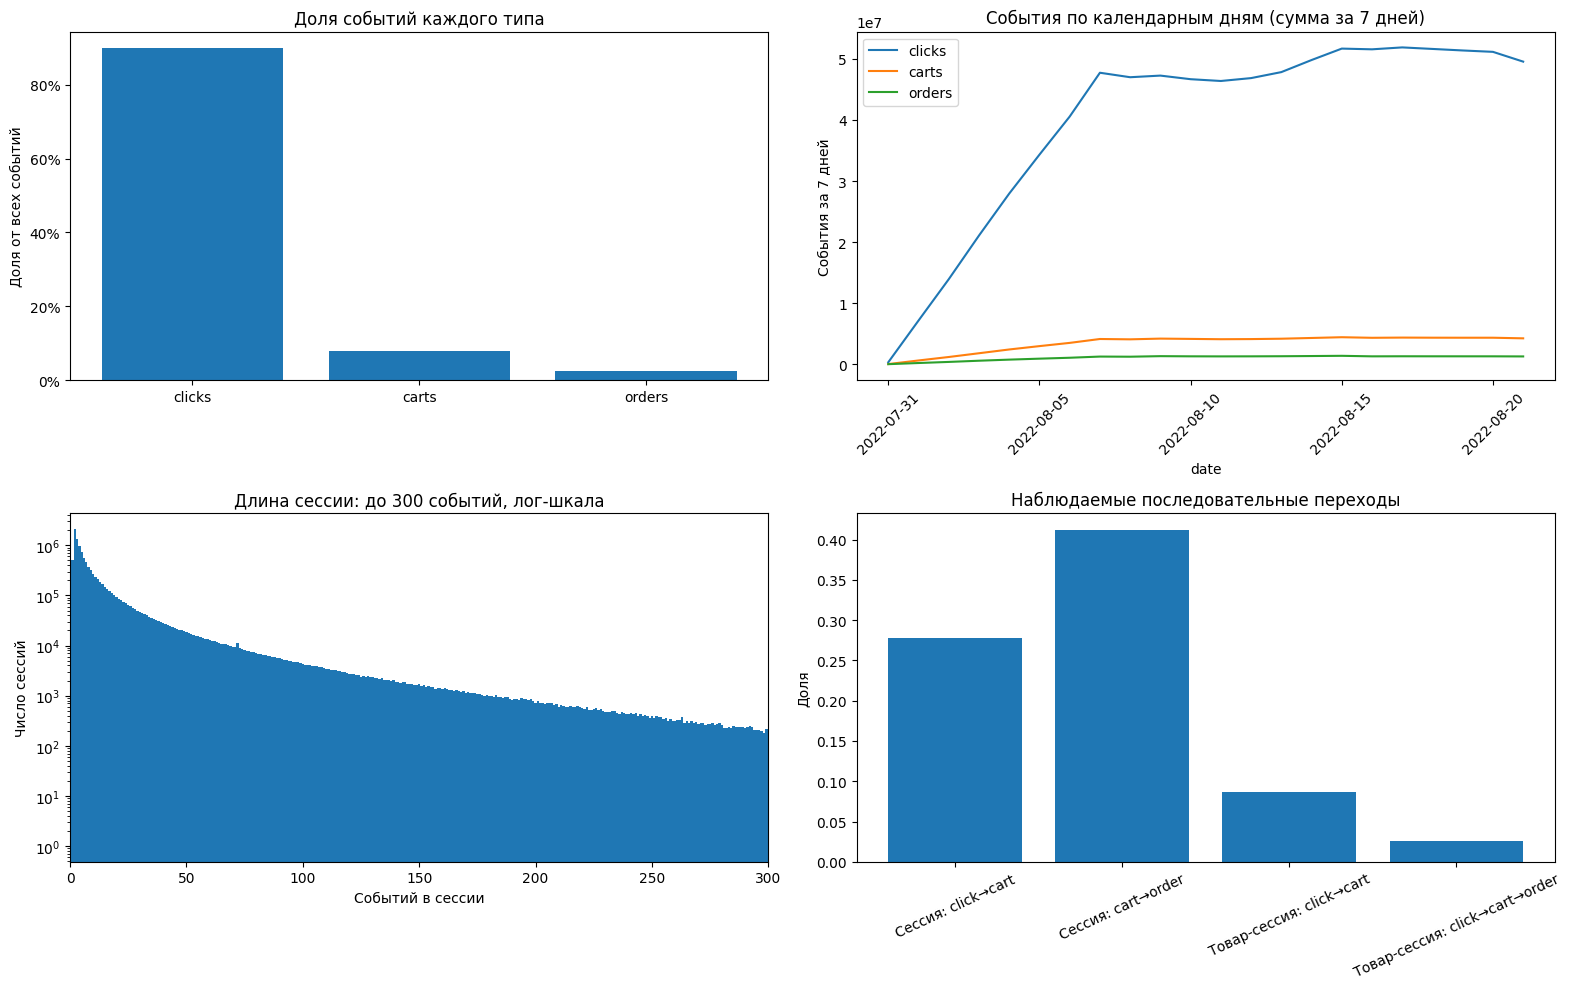

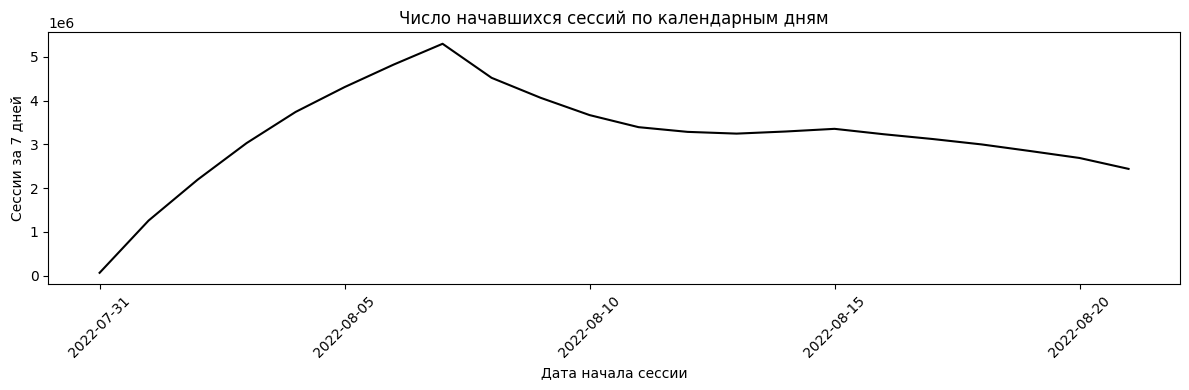

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Event mix.
event_values = [event_counts[event_type] for event_type in EVENT_TYPES]
event_shares = np.array(event_values) / max(sum(event_values), 1)
axes[0, 0].bar(EVENT_TYPES, event_shares)
axes[0, 0].set_title('Доля событий каждого типа')
axes[0, 0].set_ylabel('Доля от всех событий')
axes[0, 0].yaxis.set_major_formatter(lambda value, position: f'{value:.0%}')

# Число событий за неделю сглаживает ежедневные колебания.
daily_activity[list(EVENT_TYPES)].rolling(7, min_periods=1).sum().plot(ax=axes[0, 1])
axes[0, 1].set_title('События по календарным дням (сумма за 7 дней)')
axes[0, 1].set_ylabel('События за 7 дней')
axes[0, 1].tick_params(axis='x', rotation=45)

# Session-length distribution, with a log y-axis to show the tail.
length_x = sorted(session_length_counts)
length_y = [session_length_counts[length] for length in length_x]
axes[1, 0].bar(length_x, length_y, width=1.0)
axes[1, 0].set_xlim(0, min(max(length_x, default=0), 300))
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Длина сессии: до 300 событий, лог-шкала')
axes[1, 0].set_xlabel('Событий в сессии')
axes[1, 0].set_ylabel('Число сессий')

# Session and same-item conversion definitions side by side.
plot_metrics = [
    ('session_click_then_cart', 'Сессия: click→cart'),
    ('session_cart_then_order', 'Сессия: cart→order'),
    ('item_click_to_cart', 'Товар-сессия: click→cart'),
    ('item_click_cart_order', 'Товар-сессия: click→cart→order'),
]
plot_values = []
for name, _ in plot_metrics:
    if name in {'session_click_then_cart', 'session_cart_then_order'}:
        denominator = funnel['sessions_with_clicks'] if name == 'session_click_then_cart' else funnel['sessions_with_carts']
        numerator = funnel['sessions_click_then_cart'] if name == 'session_click_then_cart' else funnel['sessions_cart_then_order']
    elif name == 'item_click_to_cart':
        numerator, denominator = funnel['clicked_then_cart_aid_session_pairs'], funnel['clicked_aid_session_pairs']
    else:
        numerator, denominator = funnel['clicked_carted_then_order_aid_session_pairs'], funnel['clicked_aid_session_pairs']
    plot_values.append(safe_rate(numerator, denominator))
axes[1, 1].bar([label for _, label in plot_metrics], plot_values)
axes[1, 1].set_title('Наблюдаемые последовательные переходы')
axes[1, 1].set_ylabel('Доля')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

fig_sessions, ax_sessions = plt.subplots(figsize=(12, 4))
daily_session_summary['sessions'].rolling(7, min_periods=1).sum().plot(
    ax=ax_sessions, color='black'
)
ax_sessions.set_title('Число начавшихся сессий по календарным дням')
ax_sessions.set_xlabel('Дата начала сессии')
ax_sessions.set_ylabel('Сессии за 7 дней')
ax_sessions.tick_params(axis='x', rotation=45)
fig_sessions.tight_layout()
plt.show()

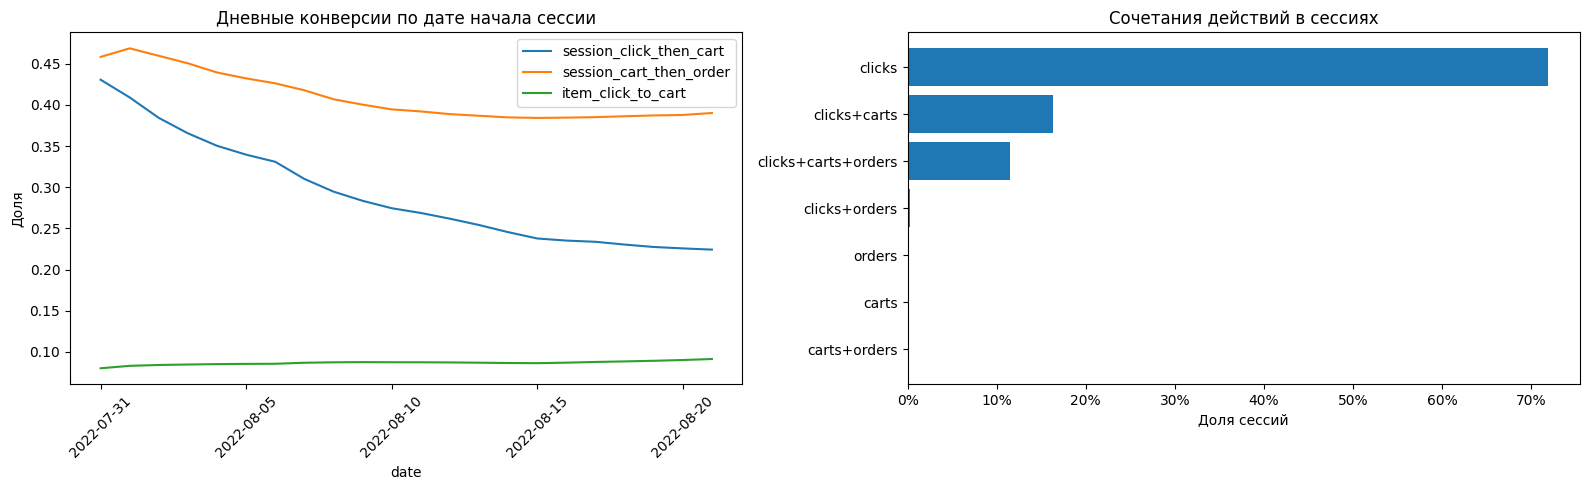

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

day_metrics_rates = daily_session_summary[
    ['session_click_then_cart', 'session_cart_then_order', 'item_click_to_cart']
].rolling(7, min_periods=1).mean()
day_metrics_rates.plot(ax=axes[0])
axes[0].set_title('Дневные конверсии по дате начала сессии')
axes[0].set_ylabel('Доля')
axes[0].tick_params(axis='x', rotation=45)

combo_labels = [row['Сочетание действий'] for row in combination_rows]
combo_shares = [row['Доля сессий'] for row in combination_rows]
axes[1].barh(combo_labels, combo_shares)
axes[1].invert_yaxis()
axes[1].set_title('Сочетания действий в сессиях')
axes[1].set_xlabel('Доля сессий')
axes[1].xaxis.set_major_formatter(lambda value, position: f'{value:.0%}')

plt.tight_layout()
plt.show()


## Экспорт сводок

Ячейка сохраняет четыре CSV-файла со сводками только по train-событиям: общую воронку, дневную активность, конверсии по датам начала train-части сессий и счётчики популярных товаров.


In [10]:
conversion_path = '/kaggle/working/eda_conversion_summary_train.csv'
daily_activity_path = '/kaggle/working/eda_daily_activity_train.csv'
daily_session_stats_path = '/kaggle/working/eda_daily_session_stats_conversion_train.csv'
top_items_path = '/kaggle/working/eda_top_items_train.csv'

conversion_summary.to_csv(conversion_path, index=False)
daily_activity.to_csv(daily_activity_path)
daily_session_summary.to_csv(daily_session_stats_path)
top_items_full.to_csv(top_items_path, index=False)

print('Сохранены отчёты:')
for report_path in (conversion_path, daily_activity_path, daily_session_stats_path, top_items_path):
    print(' ', report_path)


Сохранены отчёты:
  /kaggle/working/eda_conversion_summary_train.csv
  /kaggle/working/eda_daily_activity_train.csv
  /kaggle/working/eda_daily_session_stats_conversion_train.csv
  /kaggle/working/eda_top_items_train.csv


In [11]:
from IPython.display import Markdown

all_train_events = sum(event_counts.values())
event_shares = {
    event_type: event_counts[event_type] / max(all_train_events, 1)
    for event_type in EVENT_TYPES
}
orders_without_carts = sum(
    count for combination, count in session_type_combinations.items()
    if 'orders' in combination.split('+') and 'carts' not in combination.split('+')
)
click_to_cart_by_date = daily_session_summary['session_click_then_cart'].dropna()
full_day_rates = click_to_cart_by_date.loc[
    (click_to_cart_by_date.index >= '2022-08-01') &
    (click_to_cart_by_date.index <= '2022-08-20')
]

conclusion_lines = [
    '## Выводы',
    '',
    f'- До границы validation в train вошло **{train_sessions_count:,} сессий** с **{train_event_count:,} событиями**. В validation отнесено **{validation_event_count:,} событий** из **{validation_sessions_count:,} сессий**; **{sessions_crossing_boundary:,} сессий** имеют события по обе стороны границы.',
    f'- Доли событий в train: clicks — **{event_shares["clicks"]:.2%}**, carts — **{event_shares["carts"]:.2%}**, orders — **{event_shares["orders"]:.2%}**.',
    f'- После click в train-части сессии cart встречается в **{safe_rate(funnel["sessions_click_then_cart"], funnel["sessions_with_clicks"]):.2%}** случаев; после cart order встречается в **{safe_rate(funnel["sessions_cart_then_order"], funnel["sessions_with_carts"]):.2%}** случаев.',
    f'- Сессии с order, но без cart, составляют **{safe_rate(orders_without_carts, funnel["sessions"]):.2%}** train-сессий.',
    f'- Повторные события с уже встречавшимся в train-части сессии товаром (`aid`) составляют **{safe_rate(funnel["repeat_item_events"], funnel["item_session_pairs"]):.2%}** item-событий.',
    f'- Длина train-части сессии: медиана — **{length_summary["p50"]:.0f} событий**, среднее — **{length_summary["mean"]:.2f}**, p90 — **{length_summary["p90"]:.0f}**, p99 — **{length_summary["p99"]:.0f}**.',
]

if len(full_day_rates) >= 2:
    first_day, last_day = full_day_rates.index[0], full_day_rates.index[-1]
    conclusion_lines.append(
        f'- Доля train-сессий с переходом click → cart изменилась с **{full_day_rates.iloc[0]:.1%}** '
        f'({first_day}) до **{full_day_rates.iloc[-1]:.1%}** ({last_day}) по датам первого train-события.'
    )

display(Markdown('\n'.join(conclusion_lines)))


## Выводы

- До границы validation в train вошло **11,098,528 сессий** с **163,955,180 событиями**. В validation отнесено **52,760,916 событий** из **5,323,084 сессий**; **3,521,833 сессий** имеют события по обе стороны границы.
- Доли событий в train: clicks — **89.91%**, carts — **7.73%**, orders — **2.36%**.
- После click в train-части сессии cart встречается в **27.75%** случаев; после cart order встречается в **41.21%** случаев.
- Сессии с order, но без cart, составляют **0.30%** train-сессий.
- Повторные события с уже встречавшимся в train-части сессии товаром (`aid`) составляют **37.70%** item-событий.
- Длина train-части сессии: медиана — **5 событий**, среднее — **14.77**, p90 — **35**, p99 — **149**.
- Доля train-сессий с переходом click → cart изменилась с **38.8%** (2022-08-01) до **21.3%** (2022-08-20) по датам первого train-события.